# EDA 05 — Chuva do INMET

Aqui vou olhar os dados de chuva das estações do **estado do Rio de Janeiro, de 2021 em diante**.

Quero ver até quando existem dados, o que está faltando e quanto choveu por dia e por mês.

A chuva está em `basedosdados.br_inmet_bdmep.microdados`. Uso o cadastro `estacao` da mesma base apenas para escolher as estações do RJ.

## 0. Preparando o ambiente
Rodo o notebook de autenticação para carregar as bibliotecas e conectar ao BigQuery. Depois escolho o período da análise.

In [1]:
%run ./00_autenticacao_bigquery.ipynb

from pathlib import Path
import numpy as np

DATA_INICIO = pd.Timestamp("2021-01-01")
DATA_FIM = pd.Timestamp("2026-10-13")

PASTA_RAW = Path("../data/raw")
PASTA_RESULTADOS = Path("../data/processed/inmet_rj")
PASTA_RAW.mkdir(parents=True, exist_ok=True)
PASTA_RESULTADOS.mkdir(parents=True, exist_ok=True)


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\VitorCoutoFilho\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


Ambiente pronto! Execute a próxima célula para autenticar.


Downloading:   0%|          |

Downloading: 100%|██████████|

,conexao_ok
0,1


Autenticação concluída! Projeto: etlchamadosrj


## 1. Quais estações vou usar?
Pego as estações com município cadastrado no estado do Rio de Janeiro. O código IBGE desses municípios começa com `33`.

In [2]:
consulta_estacoes = """
SELECT id_estacao, estacao, id_municipio, data_fundacao
FROM `basedosdados.br_inmet_bdmep.estacao`
WHERE STARTS_WITH(id_municipio, '33')
ORDER BY id_estacao
"""

estacoes = bd.read_sql(consulta_estacoes, billing_project_id=BILLING_PROJECT_ID)
estacoes["data_fundacao"] = pd.to_datetime(estacoes["data_fundacao"].astype(str), errors="coerce")
if estacoes["id_estacao"].isna().any() or estacoes["id_estacao"].duplicated().any():
    raise ValueError("Confira os identificadores no cadastro das estações.")

print("Estações do RJ:", len(estacoes))
display(estacoes)

Downloading:   0%|          |

Downloading: 100%|██████████|


Estações do RJ: 26


,id_estacao,estacao,id_municipio,data_fundacao
0,A601,SEROPEDICA-ECOLOGIA AGRICOLA,3305554,2000-05-24
1,A602,RIO DE JANEIRO-MARAMBAIA,3304557,2002-11-08
2,A603,DUQUE DE CAXIAS - XEREM,3301702,2002-10-21
3,A604,CAMBUCI,3300902,2002-11-20
4,A606,ARRAIAL DO CABO,3300258,2006-09-22
5,A607,CAMPOS DOS GOYTACAZES,3301009,2006-09-25
6,A608,MACAE,3304524,2006-09-22
7,A609,RESENDE,3304201,2006-09-29
8,A610,PICO DO COUTO,3303906,2006-10-22
9,A611,VALENCA,3306206,2006-09-27


## 2. Olhando uma amostra da chuva
Trago só data, hora, estação e precipitação. Se o arquivo dessa consulta já estiver salvo, leio o arquivo para não baixar tudo de novo.

In [3]:
arquivo_raw = PASTA_RAW / f"inmet_rj_horario_{DATA_INICIO:%Y%m%d}_{DATA_FIM:%Y%m%d}.parquet"

consulta_chuva = f"""
SELECT data, hora, id_estacao, precipitacao_total
FROM `basedosdados.br_inmet_bdmep.microdados`
WHERE ano BETWEEN {DATA_INICIO.year} AND {(DATA_FIM + pd.Timedelta(days=1)).year}
  AND id_estacao IN (
    SELECT id_estacao
    FROM `basedosdados.br_inmet_bdmep.estacao`
    WHERE STARTS_WITH(id_municipio, '33')
  )
"""

if arquivo_raw.exists():
    chuva = pd.read_parquet(arquivo_raw, columns=["data", "hora", "id_estacao", "precipitacao_total"])
    print("Dados lidos do arquivo salvo.")
else:
    chuva = bd.read_sql(consulta_chuva, billing_project_id=BILLING_PROJECT_ID)
    chuva["data"] = pd.to_datetime(chuva["data"].astype(str), errors="coerce")
    chuva["hora"] = chuva["hora"].astype("string")
    chuva.to_parquet(arquivo_raw, index=False)

chuva = chuva[chuva["id_estacao"].isin(estacoes["id_estacao"])].copy()
chuva["precipitacao_total"] = pd.to_numeric(chuva["precipitacao_total"], errors="coerce").astype(float)
print("Linhas carregadas:", len(chuva))
display(chuva.head(10))

Dados lidos do arquivo salvo.
Linhas carregadas: 1349040


,data,hora,id_estacao,precipitacao_total
0,2021-01-01,00:00:00,A601,0.0
1,2021-01-01,01:00:00,A601,0.0
2,2021-01-01,02:00:00,A601,0.0
3,2021-01-01,03:00:00,A601,0.0
4,2021-01-01,04:00:00,A601,0.0
5,2021-01-01,05:00:00,A601,0.0
6,2021-01-01,06:00:00,A601,0.0
7,2021-01-01,07:00:00,A601,0.0
8,2021-01-01,08:00:00,A601,0.0
9,2021-01-01,09:00:00,A601,0.0


## 3. Tamanho e período
A hora da base está em UTC. Passo para o horário do Rio antes de separar os dias. Aqui uso o dia do horário registrado; ele pode ser diferente do dia usado nos boletins oficiais do INMET.

In [4]:
datas = pd.to_datetime(chuva["data"].astype(str), errors="coerce")
horas = pd.to_timedelta(chuva["hora"].astype(str), errors="coerce")
chuva["instante_utc"] = (datas + horas).dt.tz_localize("UTC")
chuva["dia"] = chuva["instante_utc"].dt.tz_convert("America/Sao_Paulo").dt.tz_localize(None).dt.normalize()

# Uma medição horária deve ter uma data válida e uma hora cheia entre 0h e 23h.
horario_valido = datas.notna() & horas.notna() & horas.ge(pd.Timedelta(0)) & horas.lt(pd.Timedelta(days=1))
horario_valido = horario_valido & horas.dt.total_seconds().mod(3600).eq(0)
print("Linhas com data ou hora inválida:", int((~horario_valido).sum()))
print("Última data UTC carregada:", datas.max())
chuva = chuva.loc[horario_valido & chuva["dia"].between(DATA_INICIO, DATA_FIM)].copy()
if chuva.empty:
    raise ValueError("Não há medições válidas no período escolhido.")

print("Linhas no período local:", len(chuva))
print("Estações:", chuva["id_estacao"].nunique())
print("Primeiro dia:", chuva["dia"].min())
print("Último dia com registro:", chuva["dia"].max())

Linhas com data ou hora inválida: 0
Última data UTC carregada: 2026-02-28 00:00:00


Linhas no período local: 1348965
Estações: 26
Primeiro dia: 2021-01-01 00:00:00
Último dia com registro: 2026-02-28 00:00:00


## 4. Valores faltando e valores estranhos
Zero é uma medição válida de ausência de chuva. Valores nulos, negativos ou infinitos não entram nas somas. Um valor alto continua na análise para ser conferido depois.

In [5]:
valores = chuva["precipitacao_total"]
resumo_valores = pd.Series({
    "Nulos": valores.isna().sum(),
    "Negativos finitos": (np.isfinite(valores) & valores.lt(0)).sum(),
    "Infinitos": (valores.notna() & ~np.isfinite(valores)).sum(),
    "Zero": valores.eq(0).sum(),
    "Positivos finitos": (np.isfinite(valores) & valores.gt(0)).sum(),
})
display(resumo_valores.to_frame("linhas"))

,linhas
Nulos,101043
Negativos finitos,0
Infinitos,0
Zero,1144041
Positivos finitos,103881


## 5. Existem registros repetidos?
Confiro a estação e o horário juntos. Repetições iguais contam uma vez. Se os valores da mesma hora são diferentes, deixo essa hora sem um valor válido.

In [6]:
chave = ["id_estacao", "instante_utc"]
print("Linhas repetidas além da primeira:", int(chuva.duplicated(chave).sum()))

valores_por_hora = chuva.groupby(chave)["precipitacao_total"].nunique(dropna=False)
horas_conflitantes = valores_por_hora[valores_por_hora > 1].reset_index()[chave]
horas_conflitantes["conflito"] = True
print("Horas com valores diferentes:", len(horas_conflitantes))

chuva = chuva.drop_duplicates(chave).copy()
chuva = chuva.merge(horas_conflitantes, on=chave, how="left", validate="one_to_one")
chuva.loc[chuva["conflito"].eq(True), "precipitacao_total"] = np.nan

# Deixo os valores inválidos como ausentes, sem trocar por zero.
valida = np.isfinite(chuva["precipitacao_total"]) & chuva["precipitacao_total"].ge(0)
chuva.loc[~valida, "precipitacao_total"] = np.nan

Linhas repetidas além da primeira: 208416


Horas com valores diferentes: 191


## 6. Como são os valores por hora?
Mostro um resumo e um gráfico só das horas com chuva. Uso a escala logarítmica na contagem para conseguir ver também os valores menos frequentes.

count    1.057838e+06
mean     1.621585e-01
std      1.297753e+00
min      0.000000e+00
50%      0.000000e+00
90%      0.000000e+00
99%      3.800000e+00
max      1.310000e+02
Name: precipitacao_total, dtype: float64

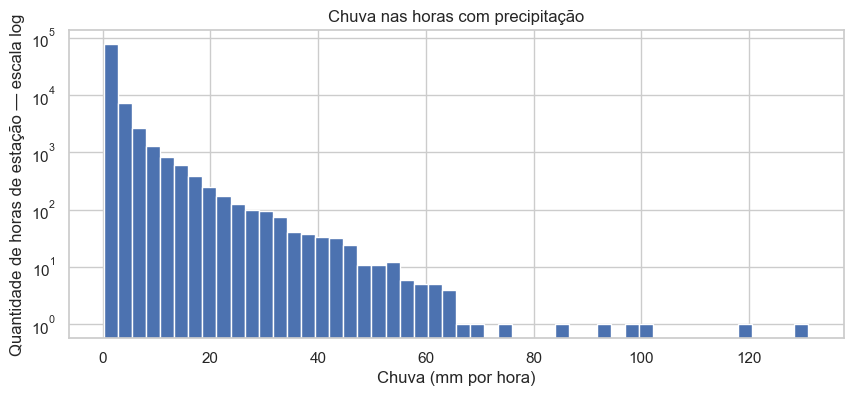

In [7]:
display(chuva["precipitacao_total"].describe(percentiles=[0.5, 0.9, 0.99]))

chuva.loc[chuva["precipitacao_total"] > 0, "precipitacao_total"].hist(bins=50, log=True, figsize=(10, 4))
plt.title("Chuva nas horas com precipitação")
plt.xlabel("Chuva (mm por hora)")
plt.ylabel("Quantidade de horas de estação — escala log")
plt.show()

## 7. Chuva por dia em cada estação
Somo as horas válidas e conto quantas existem. Só considero o total diário completo com **24 horas válidas**. Uma soma de menos horas fica separada como parcial.

In [8]:
grupo_dia = chuva.groupby(["id_estacao", "dia"])
chuva_dia = grupo_dia.agg(
    horas_registradas=("instante_utc", "size"),
    horas_validas=("precipitacao_total", "count"),
)
chuva_dia["chuva_observada_mm"] = grupo_dia["precipitacao_total"].sum(min_count=1)

# Incluo até os dias sem registro, para conseguir enxergar as lacunas.
calendario = pd.date_range(DATA_INICIO, DATA_FIM)
indice = pd.MultiIndex.from_product([estacoes["id_estacao"], calendario], names=["id_estacao", "dia"])
chuva_dia = chuva_dia.reindex(indice).reset_index()
chuva_dia[["horas_registradas", "horas_validas"]] = chuva_dia[["horas_registradas", "horas_validas"]].fillna(0).astype(int)
chuva_dia["dia_completo"] = chuva_dia["horas_validas"].eq(24)
chuva_dia["chuva_mm"] = chuva_dia["chuva_observada_mm"].where(chuva_dia["dia_completo"])
chuva_dia = chuva_dia.merge(estacoes, on="id_estacao", how="left", validate="many_to_one")
chuva_dia["esperado"] = chuva_dia["dia"].ge(chuva_dia["data_fundacao"].fillna(DATA_INICIO))

print("Dias de estação completos:", int(chuva_dia["dia_completo"].sum()))
display(chuva_dia.head())

Dias de estação completos: 41280


,id_estacao,dia,horas_registradas,horas_validas,chuva_observada_mm,dia_completo,chuva_mm,estacao,id_municipio,data_fundacao,esperado
0,A601,2021-01-01,24,24,1.8,True,1.8,SEROPEDICA-ECOLOGIA AGRICOLA,3305554,2000-05-24,True
1,A601,2021-01-02,24,24,16.0,True,16.0,SEROPEDICA-ECOLOGIA AGRICOLA,3305554,2000-05-24,True
2,A601,2021-01-03,24,24,10.0,True,10.0,SEROPEDICA-ECOLOGIA AGRICOLA,3305554,2000-05-24,True
3,A601,2021-01-04,24,24,0.2,True,0.2,SEROPEDICA-ECOLOGIA AGRICOLA,3305554,2000-05-24,True
4,A601,2021-01-05,24,24,0.0,True,0.0,SEROPEDICA-ECOLOGIA AGRICOLA,3305554,2000-05-24,True


**Cuidado que aprendi:** dia sem medição não é dia seco. Por isso os dias sem dados ficam sem valor de chuva. Um mesmo dia pode aparecer em várias estações.

## 8. Quais estações têm mais falhas?
Calculo a porcentagem de dias completos até a última data com registro. Deixo fora os dias anteriores à fundação da estação.

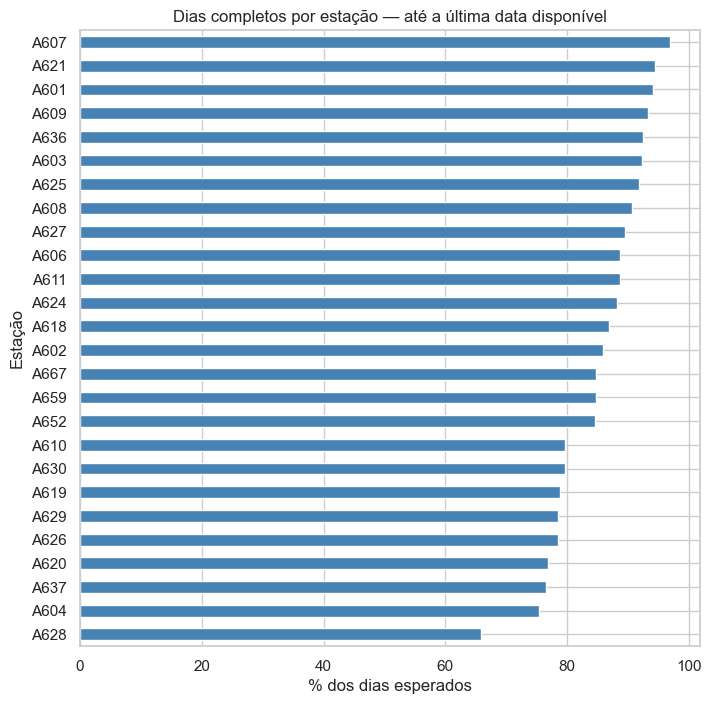

In [9]:
ultimo_dia = chuva["dia"].max()
dias_esperados = chuva_dia[chuva_dia["esperado"] & chuva_dia["dia"].le(ultimo_dia)]
qualidade_estacoes = dias_esperados.groupby("id_estacao")["dia_completo"].mean() * 100
qualidade_estacoes = qualidade_estacoes.reindex(estacoes["id_estacao"])

qualidade_estacoes.sort_values().plot(kind="barh", figsize=(8, 8), color="steelblue")
plt.title("Dias completos por estação — até a última data disponível")
plt.xlabel("% dos dias esperados")
plt.ylabel("Estação")
plt.show()

## 9. Os dias com mais chuva
Uso apenas os dias completos para ver os maiores totais. Isso evita comparar a soma de um dia inteiro com a de poucas horas.

In [10]:
dias_completos = chuva_dia[chuva_dia["dia_completo"]].copy()
display(dias_completos["chuva_mm"].describe(percentiles=[0.5, 0.9, 0.99]))
print("Dias de estação com menos de 1 mm:", round(100 * dias_completos["chuva_mm"].lt(1).mean(), 1), "%")

print("Os 10 maiores totais diários completos:")
display(dias_completos.nlargest(10, "chuva_mm")[["id_estacao", "estacao", "dia", "chuva_mm"]])

count    41280.000000
mean         3.926827
std         11.279004
min          0.000000
50%          0.000000
90%         12.200000
99%         52.642000
max        288.200000
Name: chuva_mm, dtype: float64

Dias de estação com menos de 1 mm: 70.9 %
Os 10 maiores totais diários completos:


,id_estacao,estacao,dia,chuva_mm
53567,A667,SAQUAREMA - SAMPAIO CORREIA,2023-02-07,288.2
53255,A667,SAQUAREMA - SAMPAIO CORREIA,2022-04-01,249.6
22675,A618,TERESOPOLIS-PARQUE NACIONAL,2025-04-05,247.4
38459,A628,ANGRA DOS REIS,2022-03-20,228.0
26521,A620,CAMPOS DOS GOYTACAZES - SAO TOME,2024-03-23,213.6
25114,A619,PARATY,2026-02-26,198.4
38500,A628,ANGRA DOS REIS,2022-04-30,187.6
23686,A619,PARATY,2022-03-31,185.6
21790,A618,TERESOPOLIS-PARQUE NACIONAL,2022-11-02,184.2
38471,A628,ANGRA DOS REIS,2022-04-01,179.6


## 10. Média de chuva por dia
Faço a média das estações com dia completo. Também conto quantas entraram na conta. A quantidade pode mudar a cada dia, e essa média representa os pontos medidos, não toda a área do estado.

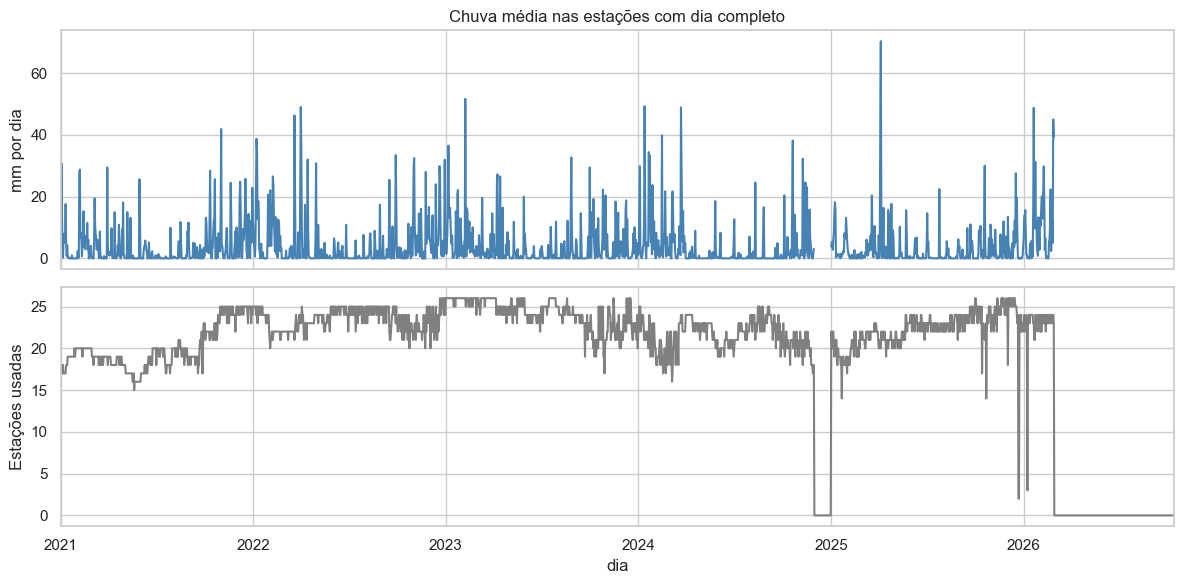

In [11]:
chuva_media = dias_completos.groupby("dia").agg(
    chuva_mm=("chuva_mm", "mean"),
    estacoes_validas=("id_estacao", "nunique"),
).reindex(calendario)
chuva_media.index.name = "dia"
chuva_media["estacoes_validas"] = chuva_media["estacoes_validas"].fillna(0).astype(int)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
chuva_media["chuva_mm"].plot(ax=axes[0], color="steelblue")
axes[0].set_title("Chuva média nas estações com dia completo")
axes[0].set_ylabel("mm por dia")
chuva_media["estacoes_validas"].plot(ax=axes[1], color="gray")
axes[1].set_ylabel("Estações usadas")
plt.tight_layout()
plt.show()

## 11. Chuva por mês
Somo a média diária e conto quantos dias têm dados. Só preencho o total mensal quando todos os dias do mês estão disponíveis. A soma dos dias disponíveis também fica guardada, mas pode ser parcial.

,dias_validos,chuva_observada_mm,dias_calendario,mes_completo,chuva_mm
mes,,,,,
2021-01,31,110.29,31,True,110.29
2021-02,28,168.57,28,True,168.57
2021-03,31,111.58,31,True,111.58
2021-04,30,92.85,30,True,92.85
2021-05,31,79.91,31,True,79.91
...,...,...,...,...,...
2026-06,0,NaN,30,False,NaN
2026-07,0,NaN,31,False,NaN
2026-08,0,NaN,31,False,NaN


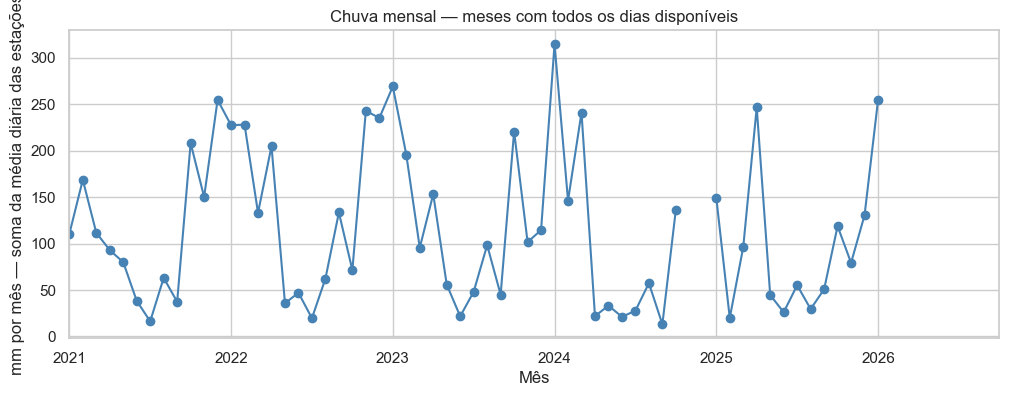

In [12]:
grupo_mes = chuva_media.groupby(chuva_media.index.to_period("M"))
chuva_mes = grupo_mes.agg(dias_validos=("chuva_mm", "count"))
chuva_mes.index.name = "mes"
chuva_mes["chuva_observada_mm"] = grupo_mes["chuva_mm"].sum(min_count=1)
chuva_mes["dias_calendario"] = chuva_mes.index.days_in_month
chuva_mes["mes_completo"] = chuva_mes["dias_validos"].eq(chuva_mes["dias_calendario"])
chuva_mes["chuva_mm"] = chuva_mes["chuva_observada_mm"].where(chuva_mes["mes_completo"])

display(chuva_mes.round(2))
chuva_mes["chuva_mm"].to_timestamp().plot(figsize=(12, 4), marker="o", color="steelblue")
plt.title("Chuva mensal — meses com todos os dias disponíveis")
plt.ylabel("mm por mês — soma da média diária das estações")
plt.xlabel("Mês")
plt.show()

## 12. Existe uma época do ano com mais chuva?
Comparo os meses completos, com uma linha para cada ano. Isso ajuda a procurar a sazonalidade, ou seja, um padrão ao longo do ano. O período é curto para tratar isso como uma normal climatológica.

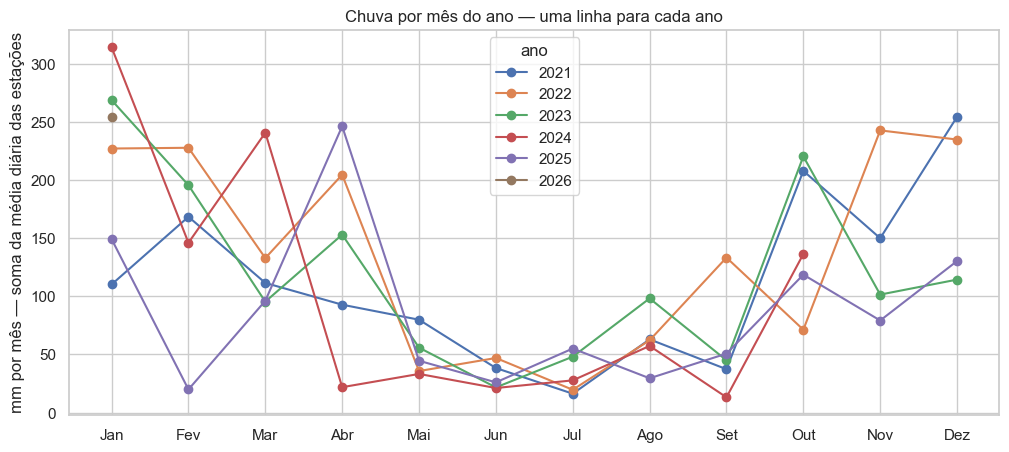

In [13]:
tabela_meses = chuva_mes[chuva_mes["mes_completo"]].copy()
tabela_meses["ano"] = tabela_meses.index.year
tabela_meses["mes_do_ano"] = tabela_meses.index.month
sazonal = tabela_meses.pivot(index="mes_do_ano", columns="ano", values="chuva_mm").reindex(range(1, 13))

if not sazonal.empty and len(sazonal.columns) > 0:
    sazonal.plot(figsize=(12, 5), marker="o")
    plt.title("Chuva por mês do ano — uma linha para cada ano")
    plt.xticks(range(1, 13), ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"])
    plt.ylabel("mm por mês — soma da média diária das estações")
    plt.xlabel("")
    plt.show()
else:
    print("Não há meses completos para comparar.")

## 13. O que aprendi sobre a chuva

- Preciso conferir as datas: pedir dados até uma data não garante que a base esteja atualizada até ela.
- Repetições de estação e horário podem aumentar a soma se eu não tratar antes.
- Um dia só tem total completo quando as 24 horas são válidas. Dados ausentes continuam ausentes.
- A média entre estações depende dos locais medidos e de quantas estações têm dados em cada dia.
- Valores muito altos precisam ser conferidos; não tiro um valor só porque ele é alto.

## 14. Salvando os resultados
Salvo as tabelas em parquet, que mantém os tipos das colunas. Na tabela mensal, cada mês é salvo como a data do primeiro dia dele.

In [14]:
chuva_dia.to_parquet(PASTA_RESULTADOS / "chuva_estacao_dia.parquet", index=False)
chuva_media.to_parquet(PASTA_RESULTADOS / "chuva_rede_dia.parquet")
chuva_mes.to_timestamp().to_parquet(PASTA_RESULTADOS / "chuva_rede_mes.parquet")
estacoes.to_parquet(PASTA_RESULTADOS / "estacoes.parquet", index=False)
qualidade_estacoes.rename("dias_completos_pct").to_frame().to_parquet(PASTA_RESULTADOS / "qualidade_estacoes.parquet")

print("Resultados salvos em:", PASTA_RESULTADOS.resolve())

Resultados salvos em: C:\Users\VitorCoutoFilho\OneDrive - Urca Energia Participações Ltda\Documentos\Vitor Couto Filho\data\processed\inmet_rj
